# Lab 2: Dual-Mode Image Segmentation (U-Net)

_The specfication for this Deep Learning Refresher Lab can be found in `lab_spec.md`_

The objective of this lab is to implement a completely custom deep CNN encoder (`U-Net`) from scratch using **Tensorflow and Keras**. We'll later use Transfer Learning to replace our custom encoder with a pre-trained feature extractor (`MobileNetV2`), freeze its weights, and connect it to our decoder using the Keras Functional API and compare the two.

> **Note**
> It is recommended to run this notebook on Colab or Kaggle with a GPU/TPU runtime if you want to run the full training.

## Milestone 1: Data Preparation

1. Download a lightweight segmentation dataset (like the Oxford-IIIT Pet Dataset or generate simple synthetic images containing solid shapes like circles/rectangles on backgrounds alongside corresponding target masks).

2. Resize all images and masks to a uniform size, such as `(128, 128)`. Normalise image arrays to `[0, 1]`. Keep masks as integers or float targets.

**The Oxford-IIIT Pet Dataset.**

Instead of dealing with full pet breed classification (which is too complex for a fast refresher), you will use its built-in **Trimap Segmentation Masks**. Every image contains a pet, and the matching target mask marks out three exact pixel classes:

-   **Class 1:** The interior of the pet.
    
-   **Class 2:** The background.
    
-   **Class 3:** The boundary/outline of the pet.


    

### Data Preparation Guide

Because this dataset is fully integrated into the `tensorflow_datasets` (TFDS) ecosystem, you don't need to manually scrape images or write complex file-parsing directories. Here is exactly how to set up your pipeline.

#### 1. Importing the Target Split

You can pull down the dataset already partitioned into training and validation groups directly through the TFDS module:

-   Use `tfds.load('oxford_iiit_pet:3.*.*', with_info=True)` to fetch both the raw pipeline dictionaries and an metadata information object.
    
-   This dataset provides an image array under the dictionary key `'image'` and its spatial mask array under `'segmentation_mask'`.
    

In [ ]:
import tensorflow_datasets as tfds
import tensorflow as tf
import matplotlib.pyplot as plt

# print("GPU Available:", tf.config.list_physical_devices('GPU'))

In [ ]:
# For running locally (it saves the dataset locally for easier loading)
dataset, info = tfds.load('oxford_iiit_pet', with_info=True, data_dir='./data') 

# If running on Colab. The line above throws error in Colal
# dataset, info = tfds.load('oxford_iiit_pet', with_info=True) 

In [3]:
dataset

{'train': <_PrefetchDataset element_spec={'file_name': TensorSpec(shape=(), dtype=tf.string, name=None), 'head_bbox': TensorSpec(shape=(4,), dtype=tf.float32, name=None), 'image': TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None), 'segmentation_mask': TensorSpec(shape=(None, None, 1), dtype=tf.uint8, name=None), 'species': TensorSpec(shape=(), dtype=tf.int64, name=None)}>,
 'test': <_PrefetchDataset element_spec={'file_name': TensorSpec(shape=(), dtype=tf.string, name=None), 'head_bbox': TensorSpec(shape=(4,), dtype=tf.float32, name=None), 'image': TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None), 'segmentation_mask': TensorSpec(shape=(None, None, 1), dtype=tf.uint8, name=None), 'species': TensorSpec(shape=(), dtype=tf.int64, name=None)}>}

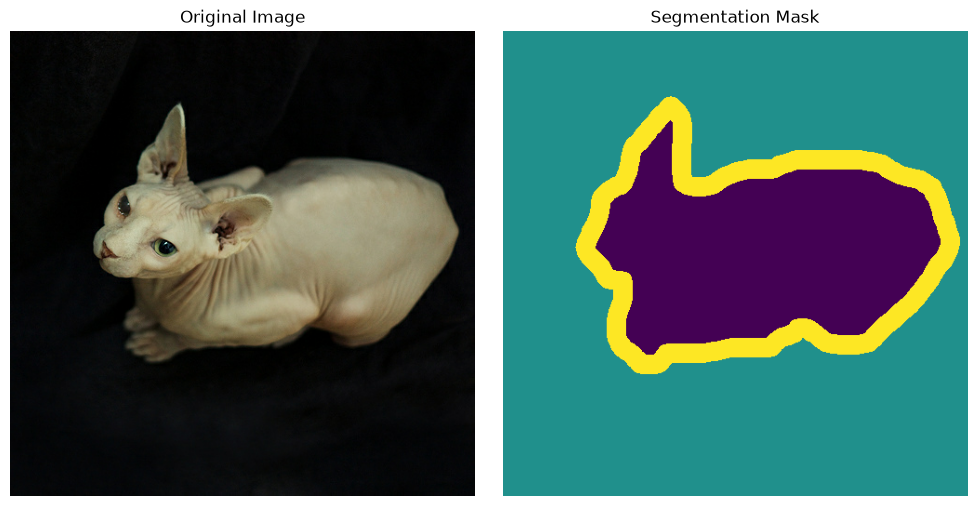

In [4]:
def plot_images(sample):
    for example in sample:
        image = example['image']
        mask = example['segmentation_mask']
        plt.figure(figsize=(10, 5))

        plt.subplot(1, 2, 1)
        plt.title("Original Image")
        plt.imshow(image)
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.title("Segmentation Mask")
        plt.imshow(mask - 1, cmap='viridis') # tfds masks are 1-indexed (1: pet, 2: background, 3: border)
        plt.axis('off')

        plt.tight_layout()
        plt.show()

plot_images(dataset['train'].take(1))

#### 2. Resolving the Target Mask Coordinates (The Trap)

The default segmentation masks in this dataset are encoded with pixel integer values of **`{1, 2, 3}`**.

-   Standard multi-class classification losses in Keras (like `SparseCategoricalCrossentropy`) require zero-based indices starting at **`0`**.
    
-   **Your Task:** In your image transformation processing block, you _must_ subtract `1` from the mask values so that the integers transform cleanly into **`{0, 1, 2}`**. If you forget this step, your loss evaluation will attempt to look up index 3, causing an out-of-bounds classification failure.
    

#### 3. Spatial and Numerical Rescaling

-   **Images:** The raw source photographs vary in shape and resolution. You will scale their dimensions down to a uniform frame size of `(128, 128, 3)` using regular bilinear resizing, and normalize their pixel values by dividing by `255.0` to pull the range into `[0.0, 1.0]`.
    
-   **Masks:** When resizing the target masks down to `(128, 128, 1)`, **do not use standard bilinear resizing.** Bilinear scaling introduces interpolated float values (e.g., trying to average a pixel between background class 0 and boundary class 2 outputs 1.0). You must use **Nearest-Neighbor interpolation** (`method=tf.image.ResizeMethod.NEAREST_NEIGHBOR`) to preserve strict integer boundaries.
    

In [5]:
BATCH_SIZE = 32
IM_SIZE = 128
BUFFER_SIZE = 1000

In [6]:
def rescaling(sample):
    rescaled_image = tf.image.resize(
        sample['image'],
        (IM_SIZE, IM_SIZE),
        method=tf.image.ResizeMethod.BILINEAR) / 255.0
    rescaled_mask = tf.image.resize(
        sample['segmentation_mask'] - 1,
        (IM_SIZE, IM_SIZE),
        method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
    return (rescaled_image, rescaled_mask)

### Step-by-Step Data Pipeline Pseudocode Strategy

When assembling this in your project notebook or script, map out your `tf.data` workflow using the following logic sequence:

1.  **Write a helper mapping function** (`load_images_and_masks(datapoint)`):
    
    -   Extract the raw image, convert it to `tf.float32`, scale it to `(128, 128)`, and divide by `255.0`.
        
    -   Extract the raw segmentation mask, scale it to `(128, 128)` using nearest-neighbor scaling, and subtract `1`.
        
    -   Return the processed tuple: `(rescaled_image, zero_indexed_mask)`.
        
2.  **Construct the optimized batching pipeline**:
    
    -   Apply `.map()` to pass your raw datasets through your helper mapping function.
        
    -   Chain on `.shuffle(buffer_size=1000)` to the training data split to ensure randomized batch propagation.
        
    -   Attach `.batch(batch_size=32)` or `.batch(64)` to assemble your tensor groups.
        
    -   Conclude with `.prefetch(buffer_size=tf.data.AUTOTUNE)`. This ensures that while your GPU is actively computing gradient transformations on batch $N$, the CPU is already preprocessing batch $N+1$ in memory, completely eliminating pipeline execution bottlenecks.

In [7]:
train_dataset = dataset['train'].map(rescaling).shuffle(buffer_size=BUFFER_SIZE).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
test_dataset = dataset['test'].map(rescaling).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

## Milestone 2: Build the Scratch U-Net (Phase A)

1. Initialize an entry `Input` node.
2. Code an encoder that down-samples twice, keeping track of your tensor variables for the skip links.
3. Code a bottleneck layer.
4. Code a decoder that up-samples twice, utilizing the `Concatenate` layer at each matching dimension.
5. Set your final layer to a `Conv2D` with 1 filter and a `'sigmoid'` activation (for binary background vs foreground parsing).Create the final model passing inputs and outputs.

In [ ]:
# Input layer
input_layer = tf.keras.Input(shape=(IM_SIZE,IM_SIZE,3))

# Encoder layer (Down Sampling) - 1
x1 = tf.keras.layers.Conv2D(filters=32,
                           kernel_size=(3,3),
                           padding="same",
                           activation="relu")(input_layer)
x1 = tf.keras.layers.Conv2D(filters=32,
                                kernel_size=(3,3),
                                padding="same",
                                activation="relu")(x1)
pool1 = tf.keras.layers.MaxPooling2D(pool_size=(2,2))(x1)

# Encoder layer (Down Sampling) - 2
x2 = tf.keras.layers.Conv2D(filters=64,
                           kernel_size=(3,3),
                           padding="same",
                           activation="relu")(pool1)
x2 = tf.keras.layers.Conv2D(filters=64,
                                kernel_size=(3,3),
                                padding="same",
                                activation="relu")(x2)
pool2 = tf.keras.layers.MaxPooling2D(pool_size=(2,2))(x2)


# Bottleneck Layer
x3 = tf.keras.layers.Conv2D(filters=128,
                           kernel_size=(3,3),
                           padding="same",
                           activation="relu")(pool2)
x3 = tf.keras.layers.Conv2D(filters=128,
                                kernel_size=(3,3),
                                padding="same",
                                activation="relu")(x3)


# Decoder layer (Up Sampling) - 1
up1 = tf.keras.layers.UpSampling2D(size=(2,2))(x3)
concat1 = tf.keras.layers.Concatenate()([up1, x2])
x4 = tf.keras.layers.Conv2D(filters=64,
                           kernel_size=(3,3),
                           padding="same",
                           activation="relu")(concat1)
x4 = tf.keras.layers.Conv2D(filters=64,
                           kernel_size=(3,3),
                           padding="same",
                           activation="relu")(x4)


# Decoder layer (Up Sampling) - 2
up2 = tf.keras.layers.UpSampling2D(size=(2,2))(x4)
concat2 = tf.keras.layers.Concatenate()([up2, x1])
x5 = tf.keras.layers.Conv2D(filters=32,
                           kernel_size=(3,3),
                           padding="same",
                           activation="relu")(concat2)
x5 = tf.keras.layers.Conv2D(filters=32,
                           kernel_size=(3,3),
                           padding="same",
                           activation="relu")(x5)


# Output layer
output_layer = tf.keras.layers.Conv2D(filters=3,
                                      kernel_size=(1,1),
                                      activation='softmax')(x5)

In [ ]:
model = tf.keras.Model(inputs=input_layer, outputs=output_layer)

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 64, 64,    │          0 │ conv2d_5[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 128, 128,  │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 96)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 128, 128,  │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_8[0][0]  

 Total params: 471,619 (1.80 MB)

 Trainable params: 471,619 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=15
)

Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 53s 234ms/step - accuracy: 0.6211 - loss: 0.8420 - val_accuracy: 0.6527 - val_loss: 0.7893
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 60s 211ms/step - accuracy: 0.6875 - loss: 0.7213 - val_accuracy: 0.7171 - val_loss: 0.7016
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 25s 200ms/step - accuracy: 0.7405 - loss: 0.6235 - val_accuracy: 0.7223 - val_loss: 0.6538
Epoch 4/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 25s 200ms/step - accuracy: 0.7629 - loss: 0.5796 - val_accuracy: 0.7786 - val_loss: 0.5486
Epoch 5/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 26s 204ms/step - accuracy: 0.7838 - loss: 0.5360 - val_accuracy: 0.7944 - val_loss: 0.5179
Epoch 6/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 26s 207ms/step - accuracy: 0.7938 - loss: 0.5142 - val_accuracy: 0.8015 - val_loss: 0.5031
Epoch 7/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 28s 220ms/step - accuracy: 0.8077 - loss: 0.4832 - val_accuracy: 0.8137 - val_loss: 0.4685
Epoch 8/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 27s 215ms/step - accuracy: 0.8110 - loss: 0

In [ ]:
model.save('./model/unet_scratch_pets.keras')

In [ ]:
loaded_unet = tf.keras.models.load_model('./model/unet_scratch_pets.keras')

1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


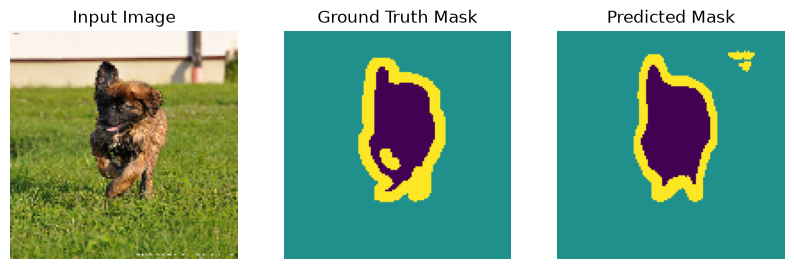

In [9]:
import matplotlib.pyplot as plt

# Grab a single test batch
for images, masks in test_dataset.take(1):
    preds = loaded_unet.predict(images)
    pred_masks = tf.argmax(preds, axis=-1)  # Extract class index (0, 1, or 2)

    # Plot sample index 0 from batch
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 3, 1)
    plt.title("Input Image")
    plt.imshow(images[0])
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.title("Ground Truth Mask")
    plt.imshow(tf.squeeze(masks[0]))
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.title("Predicted Mask")
    plt.imshow(pred_masks[0])
    plt.axis("off")

    plt.show()

## Milestone 3: Swap in the Transfer Learning Engine (Phase B)

1. Set up a fresh model construction routine.
2. Load `MobileNetV2` with frozen weights (`layer.trainable = False`).
3. Extract specific feature activation layers to serve as your new encoder skip layers.
4. Route those outputs directly into your existing Phase A decoder framework.

### Blueprint for Phase B: MobileNetV2 Backbone Construction

Here is how to set up the transfer learning encoder locally.

#### Step 1: Instantiate MobileNetV2

In [8]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128,128,3),
    include_top=False,
    weights='imagenet'
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
base_model.trainable = False

#### Step 2: Extract Intermediate Skip Connection Layers
We need activation outputs at multiple spatial resolutions (128x128, 64x64, 32x32, and the 16x16 bottleneck):

In [23]:
layer_names = [
    base_model.layers[0].name,
    "block_1_expand_relu",
    "block_3_expand_relu",
    "block_6_expand_relu",
    "block_13_expand_relu",
]

skip_outputs = [base_model.get_layer(name).output for name in layer_names]
down_stack = tf.keras.Model(inputs=base_model.input, outputs=skip_outputs)

In [24]:
# Bottleneck Layer Output
x = skip_outputs[4]

# Decoder layer (Up Sampling) - 1
up_sample1 = tf.keras.layers.UpSampling2D(size=(2,2))(x)
concatenate1 = tf.keras.layers.Concatenate()([up_sample1, skip_outputs[3]])
conv1 = tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu')(concatenate1)
conv1 = tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu')(conv1)

# Decoder layer (Up Sampling) - 2
up_sample2 = tf.keras.layers.UpSampling2D(size=(2,2))(conv1)
concatenate2 = tf.keras.layers.Concatenate()([up_sample2, skip_outputs[2]])
conv2 = tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu')(concatenate2)
conv2 = tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu')(conv2)

# Decoder layer (Up Sampling) - 3
up_sample3 = tf.keras.layers.UpSampling2D(size=(2,2))(conv2)
concatenate3 = tf.keras.layers.Concatenate()([up_sample3, skip_outputs[1]])
conv3 = tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu')(concatenate3)
conv3 = tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu')(conv3)

# Decoder layer (Up Sampling) - 3
up_sample4 = tf.keras.layers.UpSampling2D(size=(2,2))(conv3)
concatenate4 = tf.keras.layers.Concatenate()([up_sample4, skip_outputs[0]])
conv4 = tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu')(concatenate4)
conv4 = tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu')(conv4)

# Output Layer
output = tf.keras.layers.Conv2D(3, (1,1), activation='softmax')(conv4)

In [25]:
mobile_unet = tf.keras.Model(inputs=base_model.input, outputs=output)

In [26]:
mobile_unet.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,814,531 (10.74 MB)

 Trainable params: 2,198,275 (8.39 MB)

 Non-trainable params: 616,256 (2.35 MB)

In [27]:
mobile_unet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [ ]:
mobile_history = mobile_unet.fit(train_dataset, validation_data=test_dataset, epochs=15)

Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 53s 357ms/step - accuracy: 0.7998 - loss: 0.5570 - val_accuracy: 0.8746 - val_loss: 0.3311
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 40s 328ms/step - accuracy: 0.8854 - loss: 0.2982 - val_accuracy: 0.8983 - val_loss: 0.2681
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 39s 319ms/step - accuracy: 0.8990 - loss: 0.2637 - val_accuracy: 0.9008 - val_loss: 0.2673
Epoch 4/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 39s 317ms/step - accuracy: 0.9059 - loss: 0.2430 - val_accuracy: 0.9065 - val_loss: 0.2474
Epoch 5/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 41s 314ms/step - accuracy: 0.9094 - loss: 0.2331 - val_accuracy: 0.9070 - val_loss: 0.2462
Epoch 6/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 39s 323ms/step - accuracy: 0.9117 - loss: 0.2265 - val_accuracy: 0.9008 - val_loss: 0.2601
Epoch 7/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 38s 313ms/step - accuracy: 0.9150 - loss: 0.2179 - val_accuracy: 0.9076 - val_loss: 0.2534
Epoch 8/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 38s 314ms/step - accuracy: 0.9153 - loss: 0

In [ ]:
mobile_unet.save('./model/unet_mobilenet_pets.keras')

In [ ]:
loaded_unet_mobilenet = tf.keras.models.load_model('./model/unet_mobilenet_pets.keras')

1/1 ━━━━━━━━━━━━━━━━━━━━ 21s 21s/step


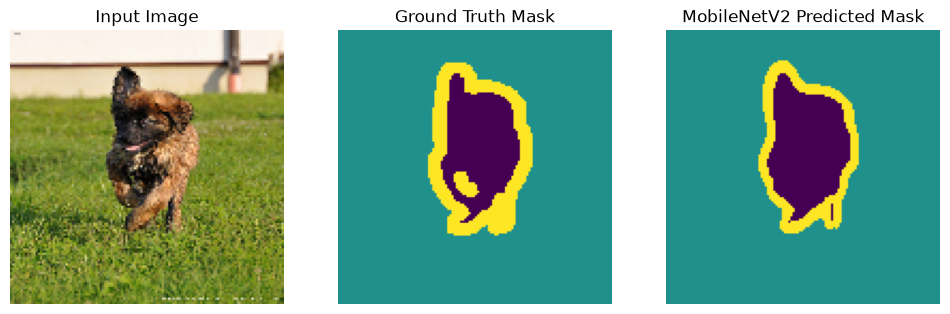

In [11]:
import matplotlib.pyplot as plt

for images, masks in test_dataset.take(1):
    preds = loaded_unet_mobilenet.predict(images)
    pred_masks = tf.argmax(preds, axis=-1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.title("Input Image")
    plt.imshow(images[0])
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.title("Ground Truth Mask")
    plt.imshow(tf.squeeze(masks[0]))
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.title("MobileNetV2 Predicted Mask")
    plt.imshow(pred_masks[0])
    plt.axis("off")

    plt.show()